## Introduction

In this assignment you will explore **Generative Adversarial Networks (GANs)** through a curated, step-by-step notebook. The notebook runs end-to-end out of the box so you can focus on the **ideas** and **observations**, not on boilerplate coding.

### Big picture (what you’ll see as you run cells)
- **Data → Model → Training → Monitoring → Samples**: we load a simple image dataset, train a generator and a critic with WGAN-GP, track a few curves, and visualize generated images over epochs.
- **Why WGAN-GP?** It encourages smooth, stable training by nudging the critic’s gradients toward unit norm, which tends to improve sample quality and reduce pathologies like mode collapse.
- **What to pay attention to:** how the samples evolve, how losses behave, and how the gradient penalty relates to stability.

### Your job in this notebook
1. **Run** the provided cells in order to understand the workflow and see the model learn.
2. **Observe & reflect** (brief notes):
   - How do samples improve across epochs?
   - What do the training curves suggest about stability?
   - Do you notice mode collapse or artifacts?

### Final task (what you will change)
- **Replace the dataset** (e.g., Fashion-MNIST or another small image dataset of similar size, can be your own dataset).
  - e.g. https://github.com/googlecreativelab/quickdraw-dataset/tree/master
- **Train another GAN** configuration of your choice (e.g., switch objective or architecture at a high level; you can reuse most of the notebook flow).
- **Report**:
  - A few representative sample grids,
  - 1–2 concise plots you find most informative,
  - **Your own exploration:** try adjusting hyperparameters (e.g., learning rate, betas, batch size, critic updates), modifying architecture (depth/width, normalization, activations), or even proposing a new loss/objective (creative/random attempts are welcome). Summarize what you changed and what you observed.

> Keep your discussion conceptual and visual: focus on *what* changes and *why* you think it happens, rather than implementation details.


In [10]:
%pip install tqdm numpy matplotlib torch torchvision pillow imageio

Note: you may need to restart the kernel to use updated packages.


In [11]:
# === Environment & Utilities ===
import os, math, time
import numpy as np
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm import tqdm
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True

def seed_everything(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
print("Device:", device)

Device: cuda


In [12]:
# === Dataloaders ===
def get_mnist_dataloaders(batch_size=128):
    tfm = transforms.Compose([
        transforms.Resize(32),
        transforms.ToTensor(),              # (0,1)
    ])
    train = datasets.MNIST(root='./data/mnist', train=True,  download=True, transform=tfm)
    test  = datasets.MNIST(root='./data/mnist', train=False, download=True, transform=tfm)
    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True,
                              num_workers=0, pin_memory=(device.type=='cuda'), drop_last=True)
    test_loader  = DataLoader(test,  batch_size=batch_size, shuffle=False,
                              num_workers=0, pin_memory=(device.type=='cuda'), drop_last=False)
    return train_loader, test_loader

def get_fashion_mnist_dataloaders(batch_size=128):
    tfm = transforms.Compose([
        transforms.Resize(32),
        transforms.ToTensor(),
    ])
    train = datasets.FashionMNIST(root='./data/fashion', train=True,  download=True, transform=tfm)
    test  = datasets.FashionMNIST(root='./data/fashion', train=False, download=True, transform=tfm)
    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True,
                              num_workers=2, pin_memory=(device.type=='cuda'), drop_last=True)
    test_loader  = DataLoader(test,  batch_size=batch_size, shuffle=False,
                              num_workers=2, pin_memory=(device.type=='cuda'), drop_last=False)
    return train_loader, test_loader

def get_lsun_dataloader(path_to_data='./data/lsun', dataset='bedroom_train', batch_size=64):
    tfm = transforms.Compose([
        transforms.Resize(128),
        transforms.CenterCrop(128),
        transforms.ToTensor(),
    ])
    dset = datasets.LSUN(root=path_to_data, classes=[dataset], transform=tfm)
    loader = DataLoader(dset, batch_size=batch_size, shuffle=True,
                        num_workers=4, pin_memory=(device.type=='cuda'), drop_last=True)
    return loader

dataset_name = 'mnist'
BATCH_SIZE = 128

if dataset_name == 'mnist':
    train_loader, _ = get_mnist_dataloaders(batch_size=BATCH_SIZE)
    IMG_SIZE = (32, 32, 1)
elif dataset_name == 'fashion_mnist':
    train_loader, _ = get_fashion_mnist_dataloaders(batch_size=BATCH_SIZE)
    IMG_SIZE = (32, 32, 1)
elif dataset_name == 'lsun':
    train_loader = get_lsun_dataloader(batch_to_data='./data/lsun',
                                       dataset='bedroom_train', batch_size=BATCH_SIZE)
    IMG_SIZE = (128, 128, 3)
else:
    raise ValueError("Unknown dataset_name")

print(f"Dataset: {dataset_name} | IMG_SIZE = {IMG_SIZE} | batches/epoch ≈ {len(train_loader)}")


Dataset: mnist | IMG_SIZE = (32, 32, 1) | batches/epoch ≈ 468


## Model Definitions

### Generator Network
The generator transforms noise $z \sim \mathcal{N}(0, I)$ into images that should match the real data distribution.

### Discriminator (Critic) Network

The discriminator acts as a **Lipschitz function** that estimates the Wasserstein distance between real and generated distributions.


In [13]:
# === Models ===
class Generator(nn.Module):
    def __init__(self, img_size, latent_dim, dim):
        """
        img_size: (H, W, C)
        """
        super().__init__()
        H, W, C = img_size
        feat_h, feat_w = H // 16, W // 16
        assert H % 16 == 0 and W % 16 == 0, "Image size should be multiples of 16"
        self.dim = dim
        self.latent_dim = latent_dim
        self.img_size = img_size
        self.feat_h, self.feat_w = int(feat_h), int(feat_w)

        self.latent_to_features = nn.Sequential(
            nn.Linear(latent_dim, 8 * dim * self.feat_h * self.feat_w),
            nn.ReLU(inplace=True),
        )
        self.features_to_image = nn.Sequential(
            nn.ConvTranspose2d(8*dim, 4*dim, 4, 2, 1, bias=False), nn.BatchNorm2d(4*dim), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(4*dim, 2*dim, 4, 2, 1, bias=False), nn.BatchNorm2d(2*dim), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(2*dim, 1*dim, 4, 2, 1, bias=False), nn.BatchNorm2d(1*dim), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(1*dim, C, 4, 2, 1),
            nn.Sigmoid()
        )

    def forward(self, z):
        x = self.latent_to_features(z)
        x = x.view(-1, 8 * self.dim, self.feat_h, self.feat_w)
        return self.features_to_image(x)

    def sample_latent(self, num_samples, device=None):
        device = device or next(self.parameters()).device
        return torch.randn((num_samples, self.latent_dim), device=device)


class Discriminator(nn.Module):
    def __init__(self, img_size, dim):
        super().__init__()
        H, W, C = img_size
        feat_h, feat_w = H // 16, W // 16
        assert H % 16 == 0 and W % 16 == 0
        self.img_size = img_size
        self.feat_h, self.feat_w = int(feat_h), int(feat_w)

        self.image_to_features = nn.Sequential(
            nn.Conv2d(C, dim, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(dim, 2*dim, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(2*dim, 4*dim, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(4*dim, 8*dim, 4, 2, 1)  # <-- no Sigmoid here
        )
        self.head = nn.Sequential(
            nn.Conv2d(8*dim, 1, 1),        # 1x1 conv to 1 channel
            nn.AdaptiveAvgPool2d(1),       # Global Average Pooling -> (B,1,1,1)
        )

    def forward(self, x):
        h = self.image_to_features(x)
        h = self.head(h).view(x.size(0), 1)  # (B,1)
        return h

In [20]:
# === Training Utils ===
@torch.no_grad()
def preview_batch(loader, n=32):
    x, _ = next(iter(loader))
    grid = make_grid(x[:n], nrow=int(math.sqrt(n)), padding=2)
    plt.figure(figsize=(4,4))
    plt.imshow(np.transpose(grid.numpy(), (1,2,0)), cmap='gray')
    plt.axis('off'); plt.title('Preview batch'); plt.show()

def gradient_penalty(D, real, fake, gp_weight=10.0):
    bsz = real.size(0)
    alpha = torch.rand(bsz, *([1] * (real.dim() - 1)), device=real.device)
    interpolated = alpha * real + (1 - alpha) * fake
    interpolated.requires_grad_(True)

    d_interpolated = D(interpolated)
    grad_outputs = torch.ones_like(d_interpolated, device=real.device)

    gradients = torch.autograd.grad(
        outputs=d_interpolated,
        inputs=interpolated,
        grad_outputs=grad_outputs,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]

    gradients = gradients.view(bsz, -1)
    grad_norm = gradients.norm(2, dim=1)               # (B,)
    gp = gp_weight * ((grad_norm - 1.0) ** 2).mean()
    return gp, grad_norm.mean()

@torch.no_grad()
def grid_from_latents(G, latents, nrow=8):
    imgs = G(latents).clamp(0,1).cpu()
    grid = make_grid(imgs, nrow=nrow, padding=2)
    return np.transpose(grid.numpy(), (1,2,0))


### Problem 4.2 — hyperparameters


### WGAN-GP Hyperparameter Experiments

I evaluated four hyperparameters: learning rate, batch size,
critic iterations (`n_critic`), and gradient penalty coefficient
(`lambda_GP`).

Six configurations were tested: five WGAN-GP configurations
and one experiment without gradient penalty.

Each experiment changes one hyperparameter relative to
the baseline while keeping the generator and critic
architectures unchanged.

All experiments were trained for 200 epochs.



In [21]:

# === Trainer (Fixed Notebook Version) ===

class Trainer:
    def __init__(self, generator, discriminator, gen_optimizer, dis_optimizer,
                 gp_weight=10.0, critic_iterations=5, print_every=50, use_cuda=None):

        self.G = generator
        self.D = discriminator
        self.G_opt = gen_optimizer
        self.D_opt = dis_optimizer

        self.gp_weight = gp_weight
        self.critic_iterations = critic_iterations
        self.print_every = print_every
        self.num_steps = 0

        # Use the device where the models were placed
        self.device = next(self.G.parameters()).device

        # Track training losses
        self.losses = {
            'G': [],
            'D': [],
            'GP': [],
            'grad_norm': []
        }

    def _critic_train_iteration(self, real_batch):

        self.D_opt.zero_grad(set_to_none=True)
        bsz = real_batch.size(0)

        # Generate fake samples without generator gradients
        z = self.G.sample_latent(bsz, device=real_batch.device)

        with torch.no_grad():
            fake = self.G(z)

        # Critic predictions
        d_real = self.D(real_batch)
        d_fake = self.D(fake)

        # Calculate gradient penalty only when enabled
        if self.gp_weight > 0:
            gp, gnorm = gradient_penalty(
                self.D,
                real_batch,
                fake,
                gp_weight=self.gp_weight
            )
        else:
            gp = torch.tensor(0.0, device=real_batch.device)
            gnorm = torch.tensor(float("nan"), device=real_batch.device)

        # Critic loss
        d_loss = d_fake.mean() - d_real.mean() + gp

        d_loss.backward()
        self.D_opt.step()

        # Save critic metrics
        self.losses['D'].append(d_loss.item())
        self.losses['GP'].append(gp.item())
        self.losses['grad_norm'].append(gnorm.item())

    def _generator_train_iteration(self, real_batch):

        self.G_opt.zero_grad(set_to_none=True)
        bsz = real_batch.size(0)

        # Sample latent noise and generate images
        z = self.G.sample_latent(bsz, device=real_batch.device)
        fake = self.G(z)

        # Generator loss
        g_loss = -self.D(fake).mean()

        g_loss.backward()
        self.G_opt.step()

        # Save generator loss
        self.losses['G'].append(g_loss.item())

    def train(self, data_loader, epochs=200,
              save_training_gif=True, gif_every_epoch=True,
              gif_name='training.gif'):

        # Get device directly from the model
        model_device = next(self.G.parameters()).device

        # Set models to training mode
        self.G.train()
        self.D.train()

        # Fixed noise for monitoring generated digits
        if save_training_gif:
            fixed_latents = self.G.sample_latent(
                64, device=model_device
            )
            progress_frames = []

        # Training loop
        for epoch in range(1, epochs + 1):

            pbar = tqdm(
                data_loader,
                desc=f"[Epoch {epoch}/{epochs}]",
                leave=False
            )

            for i, (data, *_) in enumerate(pbar):

                data = data.to(model_device, non_blocking=True)
                self.num_steps += 1

                # Train critic
                self._critic_train_iteration(data)

                # Train generator every n_critic steps
                if self.num_steps % self.critic_iterations == 0:
                    self._generator_train_iteration(data)

                # Display progress
                if (i % self.print_every == 0) and len(self.losses['G']) > 0:
                    pbar.set_postfix(
                        D=f"{self.losses['D'][-1]:.3f}",
                        GP=f"{self.losses['GP'][-1]:.3f}",
                        G=f"{self.losses['G'][-1]:.3f}",
                        gN=f"{self.losses['grad_norm'][-1]:.2f}"
                    )

            # Display generated MNIST digits
            if save_training_gif and (gif_every_epoch or epoch == epochs):

                self.G.eval()
                with torch.no_grad():
                    frame = grid_from_latents(
                        self.G, fixed_latents, nrow=8
                    )
                self.G.train()

                progress_frames.append(
                    (frame * 255).astype(np.uint8)
                )

                clear_output(wait=True)

                fig, ax = plt.subplots(figsize=(4, 4))
                ax.imshow(frame, cmap='gray')
                ax.axis('off')
                ax.set_title(f"Epoch {epoch}")

                display(fig)
                plt.close(fig)

        # Return tracked losses for hyperparameter comparison
        return self.losses


In [22]:
from pathlib import Path

# Random seed for reproducibility
SEED = 42

# Folder to save experiment results
OUTPUT_ROOT = Path("wgan_gp_results")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


In [23]:

# === Instantiate models & optimizers ===
LATENT_DIM = 100
DIM        = 16
LR         = 1e-4
BETAS      = (0.9, 0.99)
EPOCHS     = 200
CRITIC_ITERS = 5
GP_WEIGHT    = 10.0
PRINT_EVERY  = 50

G = Generator(img_size=IMG_SIZE, latent_dim=LATENT_DIM, dim=DIM).to(device)
D = Discriminator(img_size=IMG_SIZE, dim=DIM).to(device)

G_opt = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS)
D_opt = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)

sum_params = lambda m: sum(p.numel() for p in m.parameters())
print(G)
print(D)
print(f"G params: {sum_params(G):,} | D params: {sum_params(D):,}")


Generator(
  (latent_to_features): Sequential(
    (0): Linear(in_features=100, out_features=512, bias=True)
    (1): ReLU(inplace=True)
  )
  (features_to_image): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(16, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Sigmoid()
  )
)
Discriminator(
  (image_to_features): Sequential(
    (0): Conv2d(1, 16, ke

In [24]:
# === Hyperparameter configurations ===

CONFIGS = [
    {
        "name": "baseline_gp",
        "lr": LR,
        "batch_size": 128,
        "n_critic": CRITIC_ITERS,
        "lambda_gp": GP_WEIGHT
    },
    {
        "name": "lower_lr_gp",
        "lr": 5e-5,
        "batch_size": 128,
        "n_critic": 5,
        "lambda_gp": 10.0
    },
    {
        "name": "larger_batch_gp",
        "lr": 1e-4,
        "batch_size": 256,
        "n_critic": 5,
        "lambda_gp": 10.0
    },
    {
        "name": "fewer_critic_gp",
        "lr": 1e-4,
        "batch_size": 128,
        "n_critic": 3,
        "lambda_gp": 10.0
    },
    {
        "name": "lower_penalty_gp",
        "lr": 1e-4,
        "batch_size": 128,
        "n_critic": 5,
        "lambda_gp": 5.0
    },
    {
        "name": "baseline_no_gp",
        "lr": 1e-4,
        "batch_size": 128,
        "n_critic": 5,
        "lambda_gp": 0.0
    }
]


=============== baseline_gp ===============


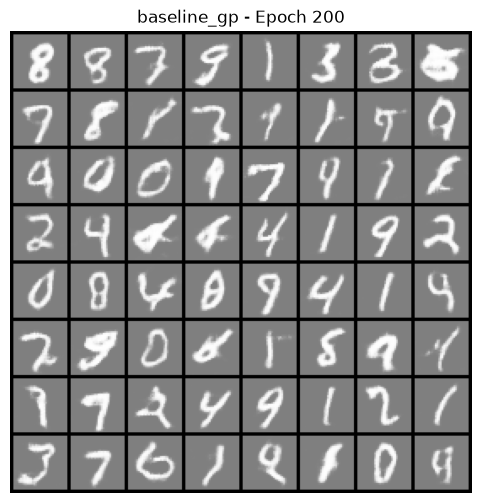

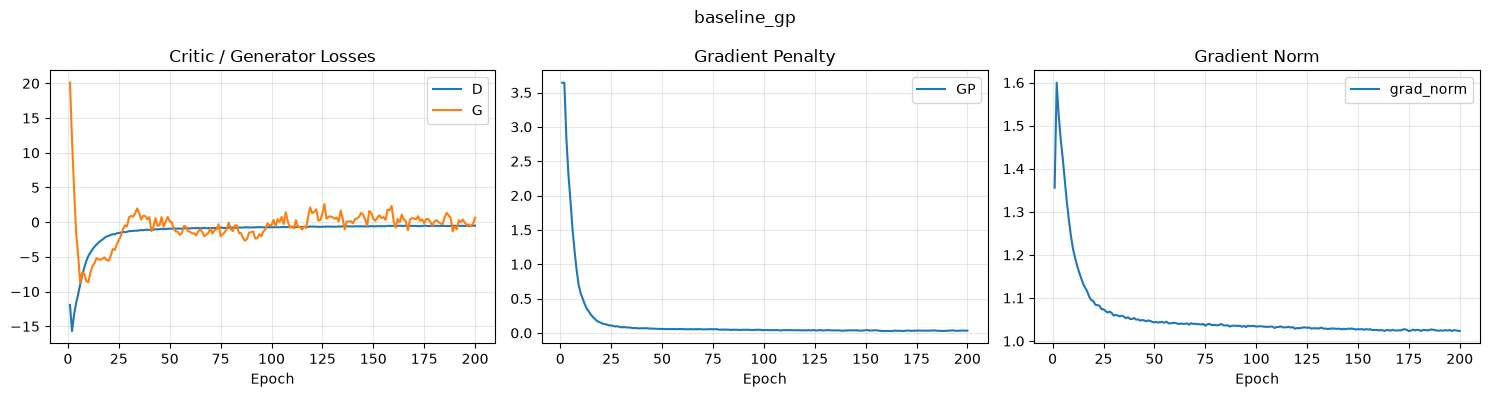

Completed experiment: baseline_gp

=============== lower_lr_gp ===============


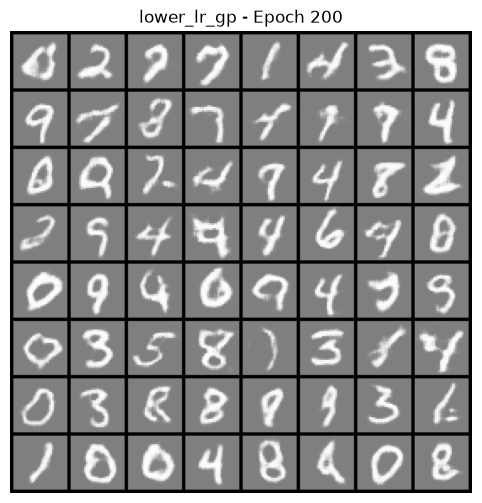

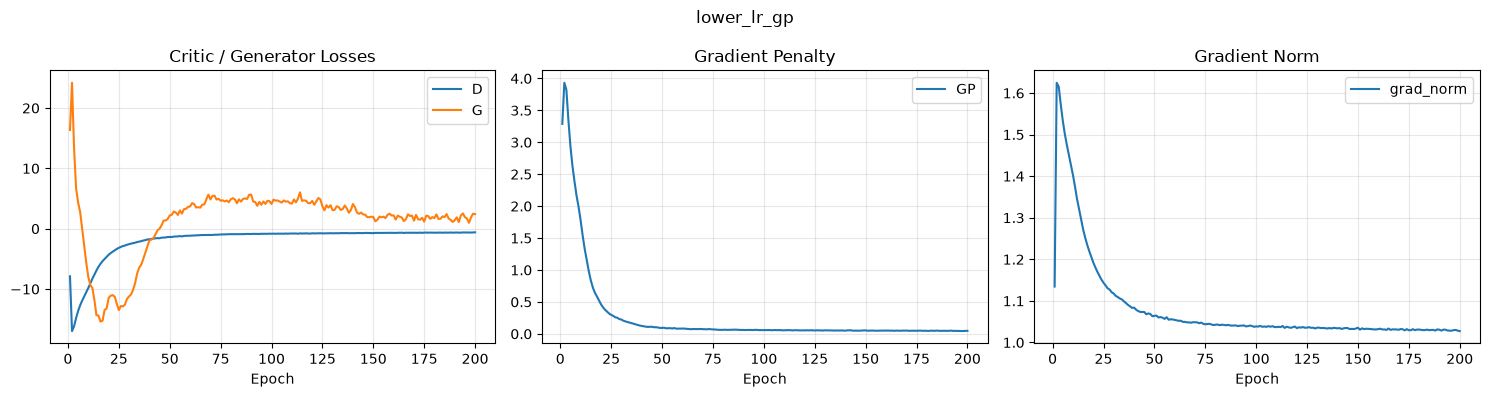

Completed experiment: lower_lr_gp

=============== larger_batch_gp ===============


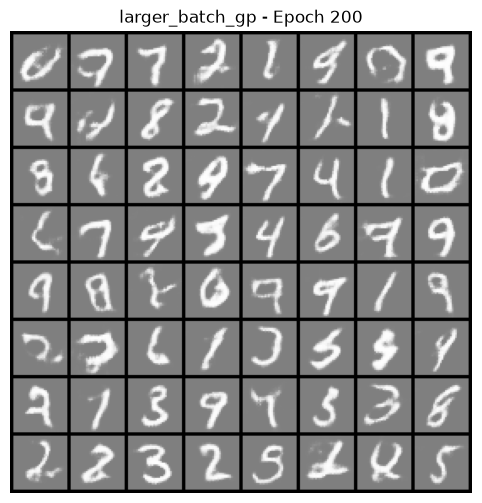

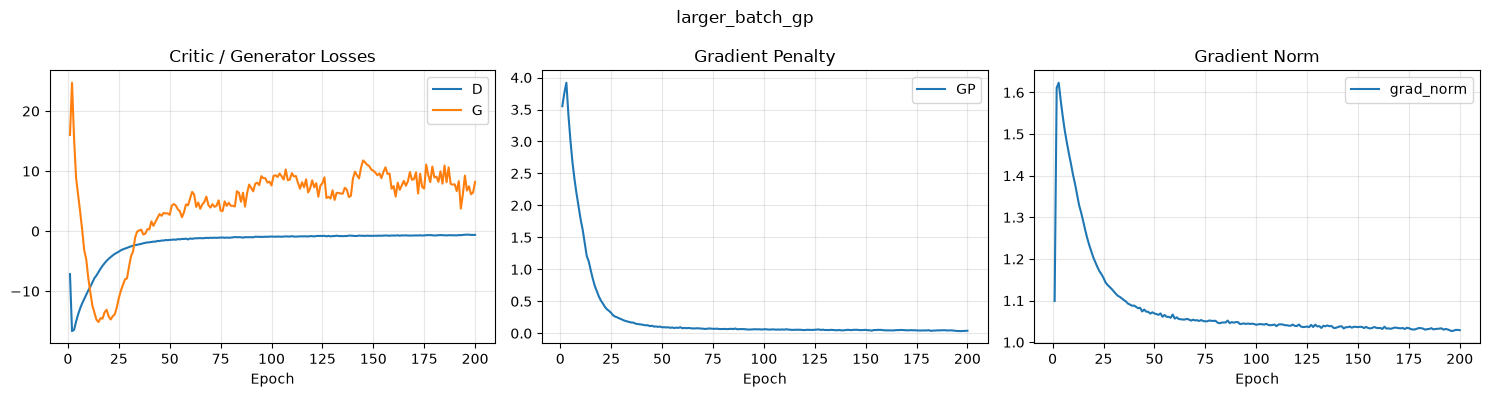

Completed experiment: larger_batch_gp

=============== fewer_critic_gp ===============


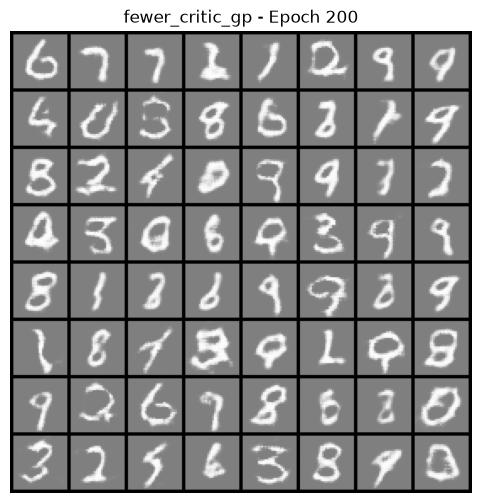

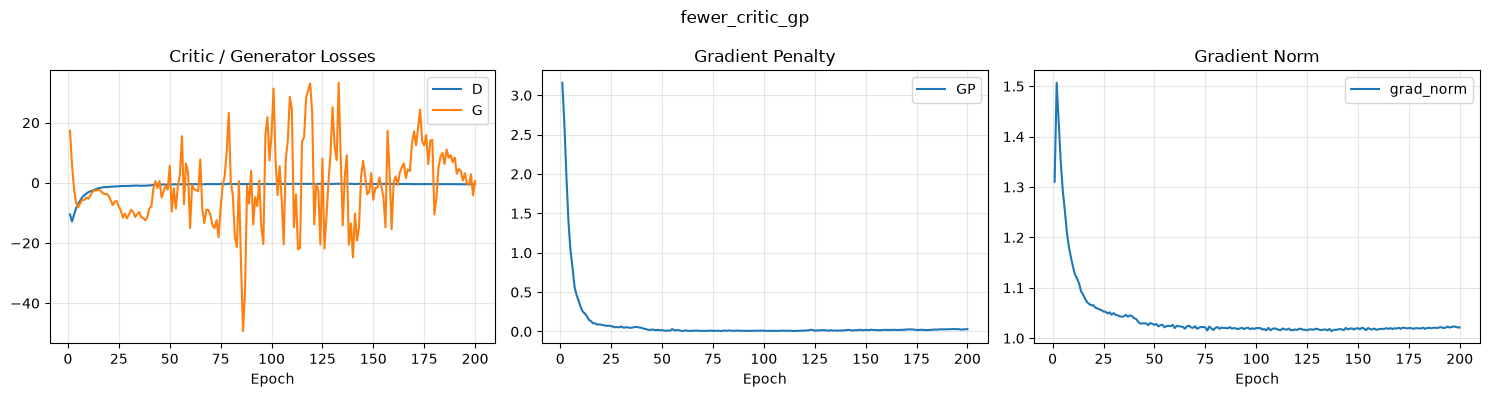

Completed experiment: fewer_critic_gp

=============== lower_penalty_gp ===============


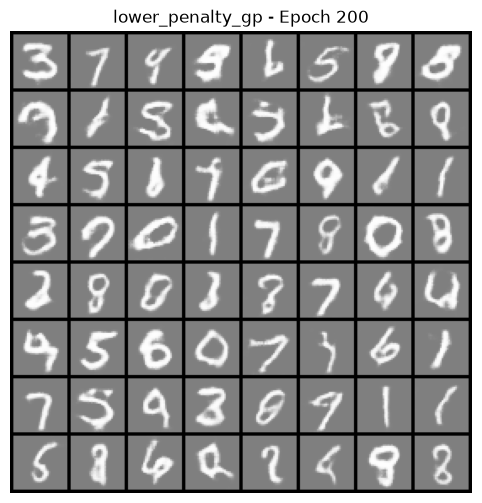

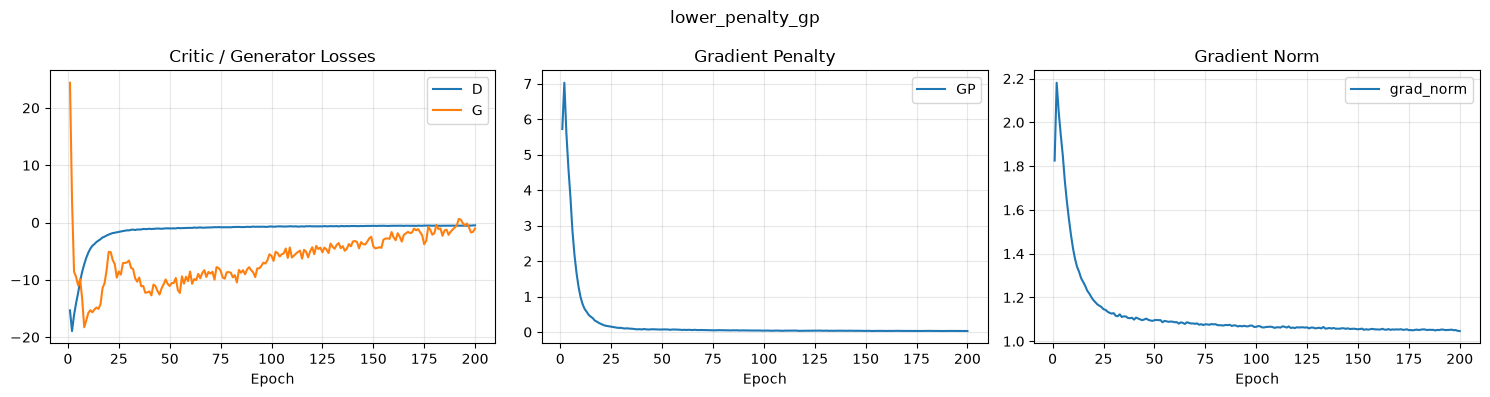

Completed experiment: lower_penalty_gp

=============== baseline_no_gp ===============


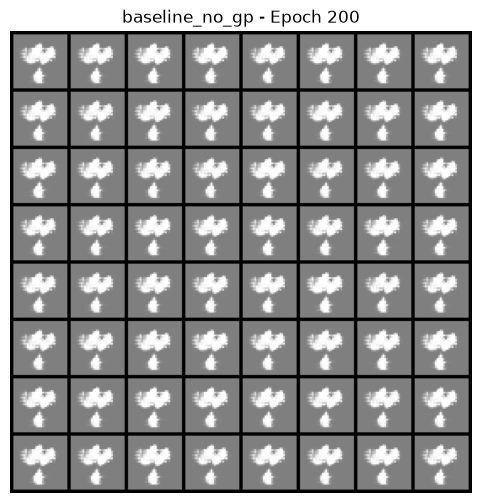

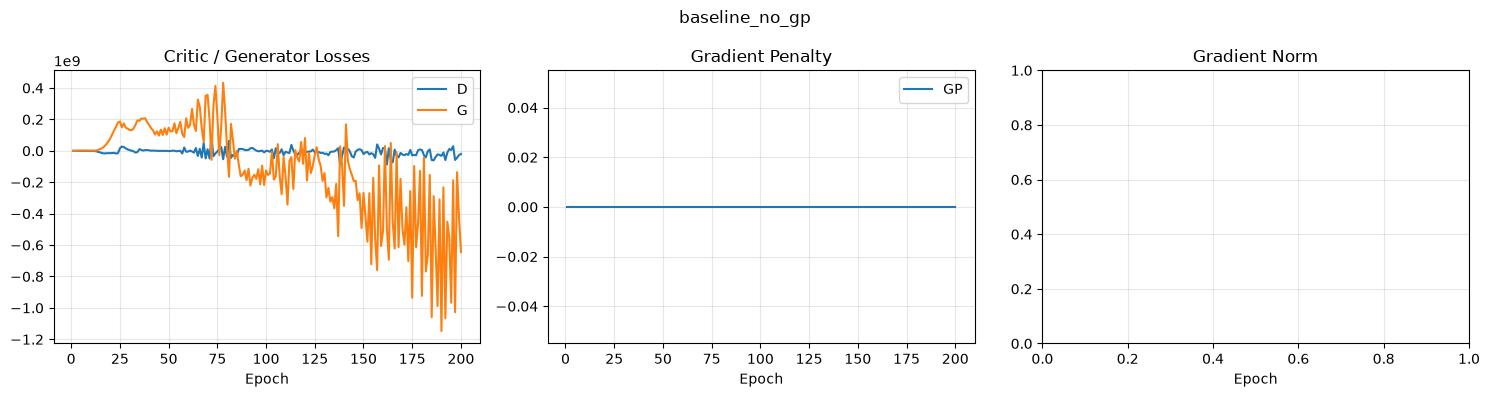

Completed experiment: baseline_no_gp

All experiments completed!
Saved results in: /workspace/wgan_gp_results


In [11]:

# === Run all experiments and save grids, curves, and metrics ===

import csv
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from torchvision.utils import save_image


# --------------------------------------------------
# 1. Plot epoch-level losses
# --------------------------------------------------

def draw_curves(history, save_path, title):

    epochs = [h["epoch"] for h in history]

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))

    plots = [
        (["D", "G"], "Critic / Generator Losses"),
        (["GP"], "Gradient Penalty"),
        (["grad_norm"], "Gradient Norm")
    ]

    for ax, (keys, caption) in zip(axs, plots):

        for key in keys:
            values = [h[key] for h in history]

            if np.isfinite(values).any():
                ax.plot(epochs, values, label=key)

        ax.set_xlabel("Epoch")
        ax.set_title(caption)
        ax.grid(alpha=0.3)

        if ax.lines:
            ax.legend()

    fig.suptitle(title)
    fig.tight_layout()

    fig.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# --------------------------------------------------
# 2. Convert raw losses to epoch averages
# --------------------------------------------------

def epoch_average_losses(losses, batches_per_epoch, n_critic,
                         num_epochs):

    # The original Trainer updates D every batch and
    # G every n_critic batches.
    # Recover the actual generator-update counts.
    history = []
    global_step = 0
    generator_update_count = 0

    for epoch in range(1, num_epochs + 1):

        d_start = (epoch - 1) * batches_per_epoch
        d_end = min(epoch * batches_per_epoch, len(losses["D"]))

        # Number of G updates before and after this epoch
        g_start = d_start // n_critic
        g_end = d_end // n_critic

        row = {"epoch": epoch}

        for key in ["D", "GP", "grad_norm"]:
            values = losses[key][d_start:d_end]
            row[key] = (
                float(np.mean(values))
                if len(values) > 0
                else float("nan")
            )

        g_values = losses["G"][g_start:g_end]
        row["G"] = (
            float(np.mean(g_values))
            if len(g_values) > 0
            else float("nan")
        )

        history.append(row)

    return history


# --------------------------------------------------
# 3. Run all hyperparameter configurations
# --------------------------------------------------

all_histories = {}

for cfg in CONFIGS:

    print("\n" + "=" * 15, cfg["name"], "=" * 15)

    # Set random seed
    seed_everything(SEED)

    # Load MNIST using experiment batch size
    train_loader, _ = get_mnist_dataloaders(
        batch_size=cfg["batch_size"]
    )

    # Create experiment output folder
    run_dir = OUTPUT_ROOT / cfg["name"]
    run_dir.mkdir(parents=True, exist_ok=True)

    # Create fresh models for every experiment
    G = Generator(
        img_size=IMG_SIZE,
        latent_dim=LATENT_DIM,
        dim=DIM
    ).to(device)

    D = Discriminator(
        img_size=IMG_SIZE,
        dim=DIM
    ).to(device)

    # Create optimizers
    G_opt = torch.optim.Adam(
        G.parameters(),
        lr=cfg["lr"],
        betas=BETAS
    )

    D_opt = torch.optim.Adam(
        D.parameters(),
        lr=cfg["lr"],
        betas=BETAS
    )

    # Initialize original fixed Trainer
    trainer = Trainer(
        generator=G,
        discriminator=D,
        gen_optimizer=G_opt,
        dis_optimizer=D_opt,
        gp_weight=cfg["lambda_gp"],
        critic_iterations=cfg["n_critic"],
        print_every=PRINT_EVERY
    )

    # Fixed latent noise for consistent comparisons
    fixed_gen = torch.Generator().manual_seed(2026)

    fixed_z = torch.randn(
        (64, LATENT_DIM),
        generator=fixed_gen
    ).to(device)

    # ----------------------------------------------
    # Train
    # ----------------------------------------------

    losses = trainer.train(
        train_loader,
        epochs=EPOCHS,
        save_training_gif=False
    )

    # Convert training-step losses into epoch averages
    history = epoch_average_losses(
        losses,
        batches_per_epoch=len(train_loader),
        n_critic=cfg["n_critic"],
        num_epochs=EPOCHS
    )

    all_histories[cfg["name"]] = history

    # ----------------------------------------------
    # Save generated MNIST digit grid
    # ----------------------------------------------

    G.eval()

    with torch.no_grad():
        fake_images = G(fixed_z).detach().cpu()

    save_image(
        fake_images,
        run_dir / f"samples_epoch_{EPOCHS:03d}.png",
        nrow=8,
        padding=2,
        normalize=True,
        value_range=(-1, 1)
    )

    # Display generated digit samples
    fig, ax = plt.subplots(figsize=(6, 6))

    from torchvision.utils import make_grid

    grid = make_grid(
        fake_images,
        nrow=8,
        normalize=True,
        value_range=(-1, 1)
    )

    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.axis("off")
    ax.set_title(f"{cfg['name']} - Epoch {EPOCHS}")

    plt.show()
    plt.close(fig)

    # ----------------------------------------------
    # Save loss curves
    # ----------------------------------------------

    draw_curves(
        history,
        run_dir / "loss_curves.png",
        cfg["name"]
    )

    # ----------------------------------------------
    # Save epoch metrics
    # ----------------------------------------------

    with open(run_dir / "metrics.csv", "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["epoch", "D", "G", "GP", "grad_norm"]
        )

        writer.writeheader()
        writer.writerows(history)

    # ----------------------------------------------
    # Save experiment configuration
    # ----------------------------------------------

    with open(run_dir / "config.json", "w") as f:
        json.dump(
            {
                **cfg,
                "epochs": EPOCHS,
                "seed": SEED,
                "betas": BETAS
            },
            f,
            indent=2
        )

    # ----------------------------------------------
    # Save trained models
    # ----------------------------------------------

    torch.save(
        {
            "generator": G.state_dict(),
            "critic": D.state_dict(),
            "config": cfg,
            "epochs": EPOCHS
        },
        run_dir / "checkpoint.pt"
    )

    print(f"Completed experiment: {cfg['name']}")


print("\nAll experiments completed!")
print("Saved results in:", OUTPUT_ROOT.resolve())



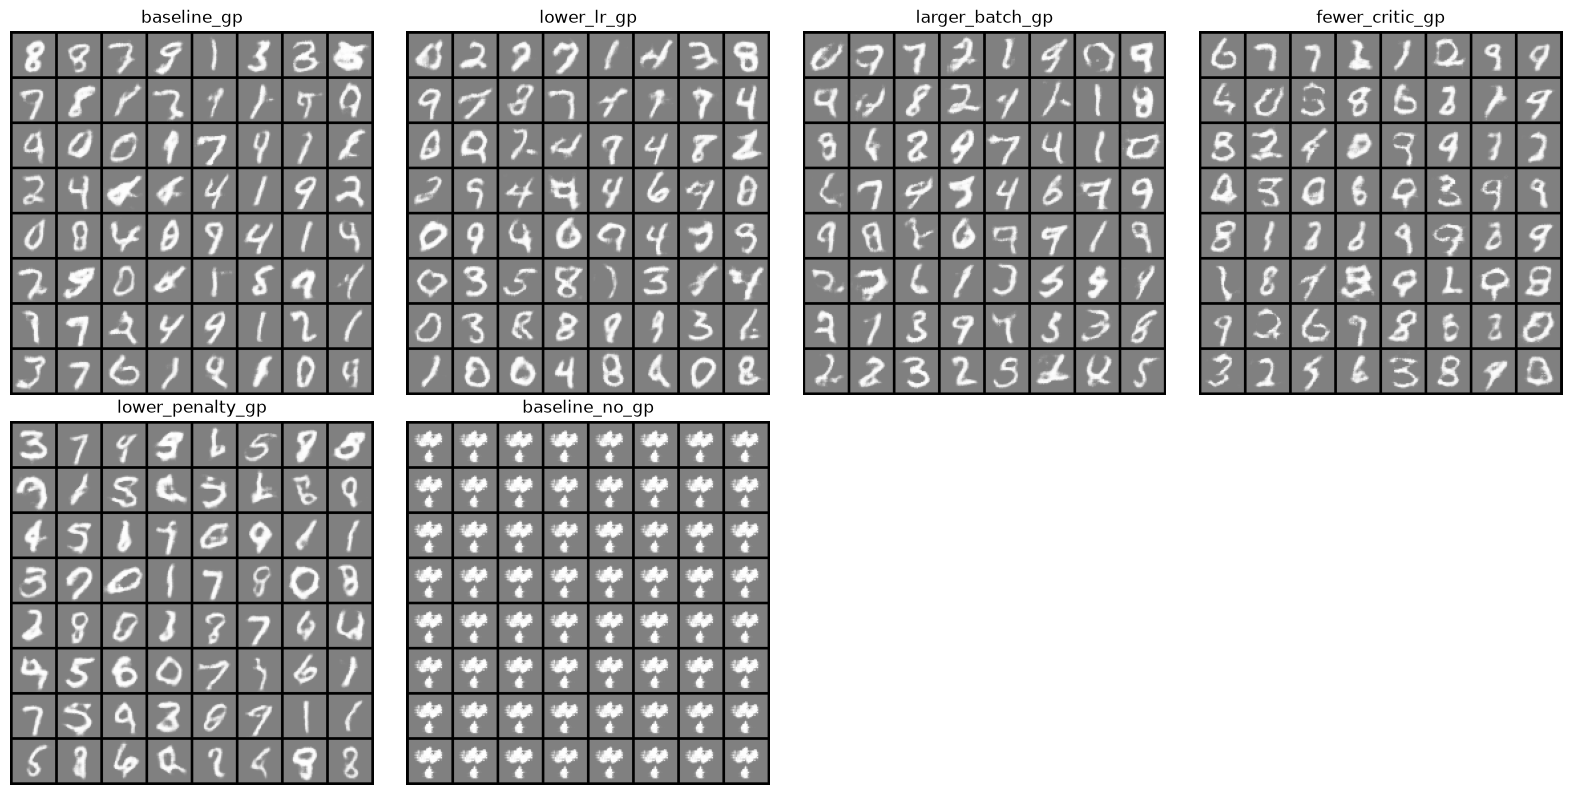

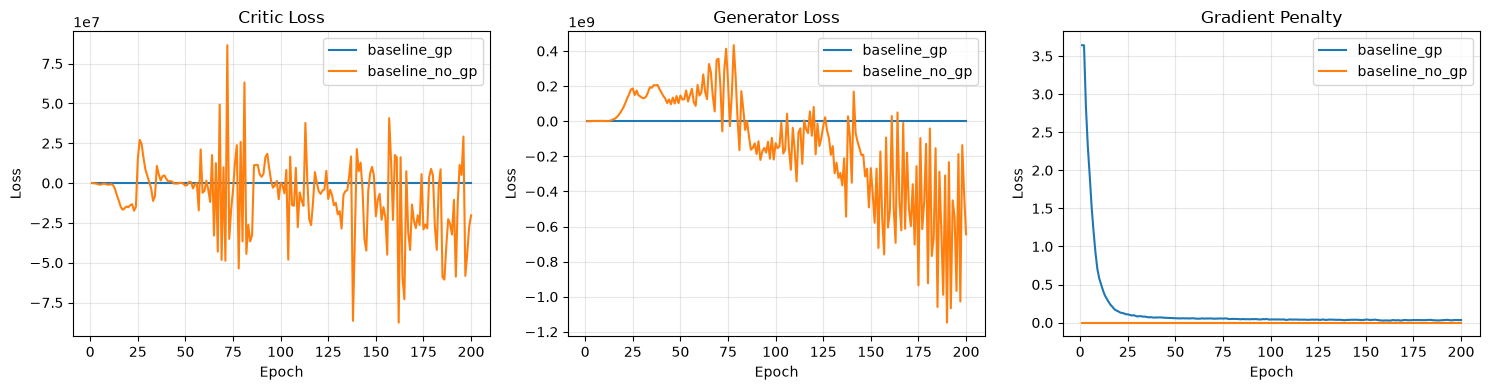


Final Epoch Summaries:

baseline_gp
  D: -0.4990
  GP: 0.0338
  grad_norm: 1.0236
  G: 0.6474

lower_lr_gp
  D: -0.5994
  GP: 0.0470
  grad_norm: 1.0274
  G: 2.4200

larger_batch_gp
  D: -0.6145
  GP: 0.0394
  grad_norm: 1.0290
  G: 8.2003

fewer_critic_gp
  D: -0.4697
  GP: 0.0304
  grad_norm: 1.0213
  G: 0.6236

lower_penalty_gp
  D: -0.4933
  GP: 0.0294
  grad_norm: 1.0464
  G: -1.0323

baseline_no_gp
  D: -20261130.3932
  GP: 0.0000
  grad_norm: nan
  G: -644193037.8617


In [13]:

# === Compare final grids and baseline/ablation statistics ===

from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Compare generated image grids
# --------------------------------------------------

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
axs = axs.flatten()

for ax, cfg in zip(axs, CONFIGS):

    path = (
        OUTPUT_ROOT
        / cfg["name"]
        / f"samples_epoch_{EPOCHS:03d}.png"
    )

    if path.exists():
        ax.imshow(Image.open(path))
        ax.set_title(cfg["name"])
    else:
        ax.text(
            0.5, 0.5,
            "Image not found",
            ha="center",
            va="center"
        )
        ax.set_title(cfg["name"])

    ax.axis("off")

for ax in axs[len(CONFIGS):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    OUTPUT_ROOT / "final_grid_comparison.png",
    dpi=180
)
plt.show()


# --------------------------------------------------
# 2. Compare with and without gradient penalty
# --------------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for label in ["baseline_gp", "baseline_no_gp"]:

    history = all_histories[label]

    epochs = [r["epoch"] for r in history]

    # Critic loss
    critic_loss = [r["D"] for r in history]

    # Generator loss
    generator_loss = [r["G"] for r in history]

    # Gradient penalty
    gp_loss = [r["GP"] for r in history]

    axs[0].plot(
        epochs,
        critic_loss,
        label=label
    )

    axs[1].plot(
        epochs,
        generator_loss,
        label=label
    )

    axs[2].plot(
        epochs,
        gp_loss,
        label=label
    )

axs[0].set_title("Critic Loss")
axs[1].set_title("Generator Loss")
axs[2].set_title("Gradient Penalty")

for ax in axs:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_ROOT / "gp_vs_no_gp.png",
    dpi=160
)

plt.show()


# --------------------------------------------------
# 3. Print final epoch summaries
# --------------------------------------------------

print("\nFinal Epoch Summaries:")

for name, history in all_histories.items():

    final_epoch = history[-1]

    print(f"\n{name}")

    for key, value in final_epoch.items():

        if key != "epoch":
            print(f"  {key}: {value:.4f}")




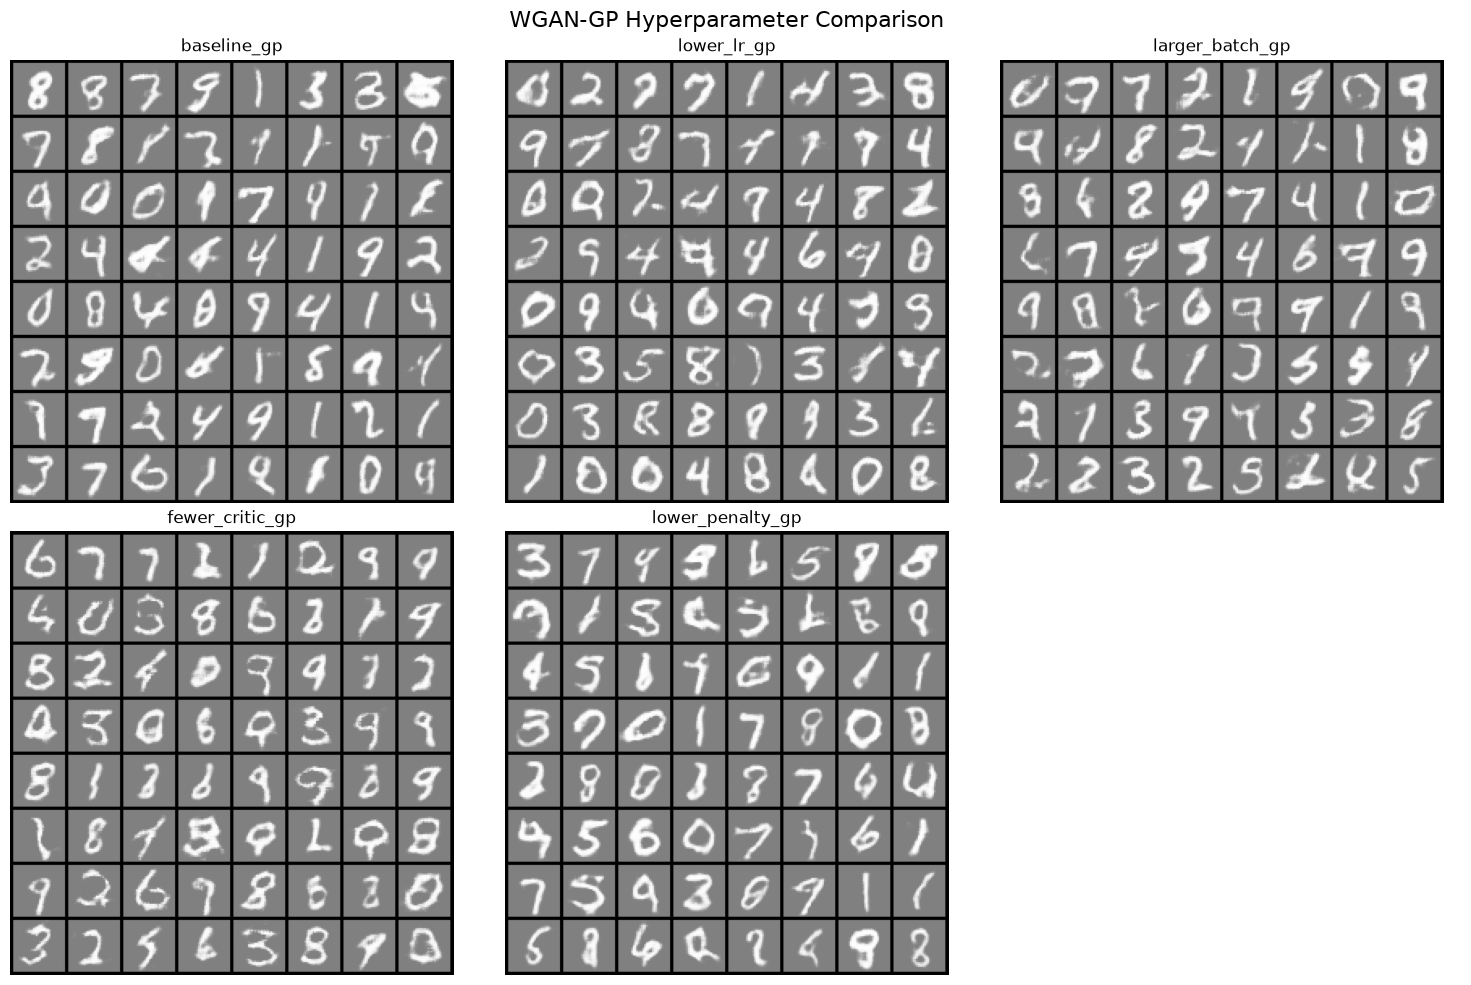

In [18]:

# === Compare all WGAN-GP generated MNIST samples ===

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

MNIST_ROOT = Path("wgan_gp_results")

runs = [
    "baseline_gp",
    "lower_lr_gp",
    "larger_batch_gp",
    "fewer_critic_gp",
    "lower_penalty_gp"
]

fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for ax, run in zip(axs.flat, runs):
    image_path = MNIST_ROOT / run / "samples_epoch_200.png"

    if image_path.exists():
        ax.imshow(Image.open(image_path))
        ax.set_title(run)
    else:
        ax.text(0.5, 0.5, "Image not found",
                ha="center", va="center")

    ax.axis("off")

for ax in list(axs.flat)[len(runs):]:
    ax.axis("off")

plt.suptitle("WGAN-GP Hyperparameter Comparison", fontsize=16)
plt.tight_layout()
plt.show()



### Best WGAN-GP Run

After training five WGAN-GP configurations for 200 epochs on MNIST, I selected `larger_batch_gp` as the best run based on visual inspection of the generated digit samples.

The selected configuration used:
- Learning rate: 0.0001
- Batch size: 256
- Critic iterations: 5
- Gradient penalty coefficient: 10
- Adam betas: (0.9, 0.99)

The generated samples showed recognizable handwritten digits with good diversity. Although some digits were distorted, the overall sample quality appeared better than in the other configurations.

At the final epoch, the critic loss was approximately -0.6145, the generator loss was 8.2003, and the average gradient norm was 1.0290.

The critic and generator loss curves are included above to illustrate training behavior across 200 epochs.

### Effect of Gradient Penalty

To isolate the effect of gradient penalty, I compared `baseline_gp` (`lambda_GP = 10`) with `baseline_no_gp` (`lambda_GP = 0`), keeping the remaining hyperparameters unchanged.

With gradient penalty, training maintained controlled critic gradients. The final baseline gradient norm was approximately 1.024, close to the target value of 1.

Without gradient penalty, the critic and generator losses grew to extremely large magnitudes, indicating numerical instability and uncontrolled critic scores.

These results suggest that gradient penalty improved training stability by encouraging the critic to satisfy the Lipschitz constraint.

### Conclusion

Among the evaluated configurations, `larger_batch_gp` was selected based on qualitative image quality and diversity. The gradient penalty comparison also demonstrated that gradient regularization was important for stable WGAN training.


### Best WGAN-GP Run: Generated MNIST Digits


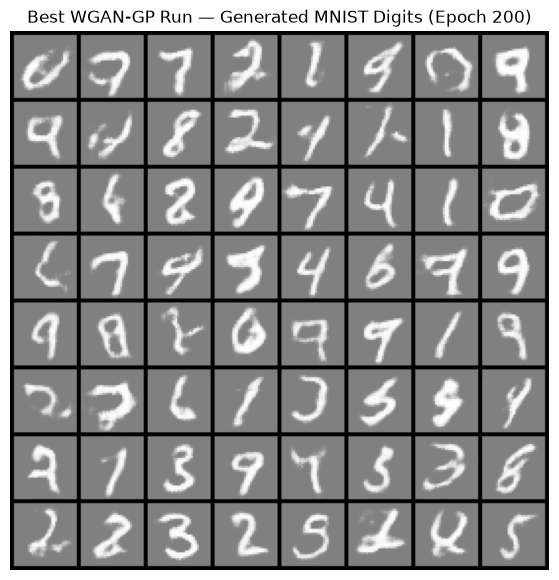

In [1]:
# === Best WGAN-GP Run: Generated MNIST Digits ===

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

MNIST_ROOT = Path("wgan_gp_results")
BEST_RUN = "larger_batch_gp"

image_path = (
    MNIST_ROOT / BEST_RUN /
    "samples_epoch_200.png"
)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(Image.open(image_path))
ax.axis("off")
ax.set_title("Best WGAN-GP Run — Generated MNIST Digits (Epoch 200)")
plt.show()


### Best WGAN-GP Run: Critic and Generator Loss Curves

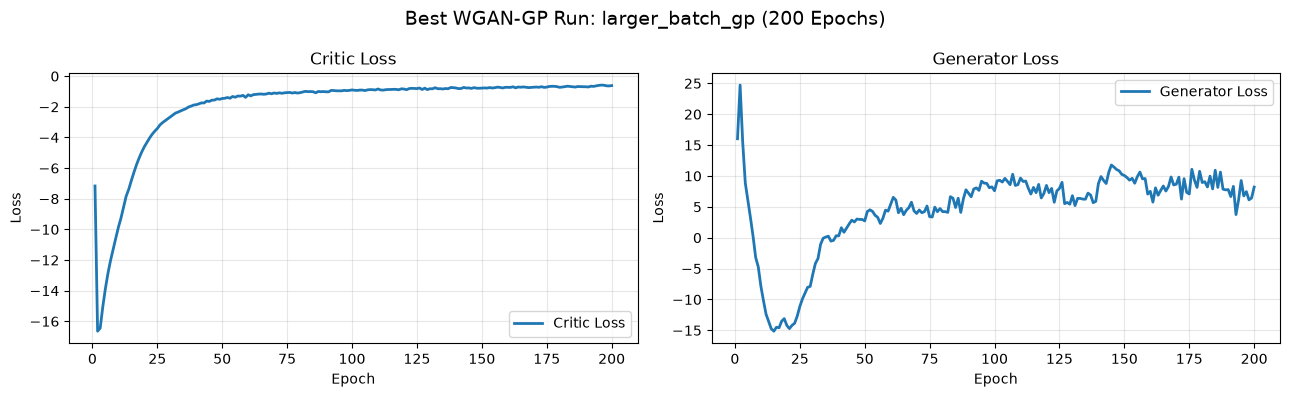

Best Run: larger_batch_gp
Final Critic Loss: -0.6145
Final Generator Loss: 8.2003
Saved loss curves to: wgan_gp_results/larger_batch_gp/best_run_loss_curves.png


In [4]:

# === Best WGAN-GP Run: Critic and Generator Loss Curves ===

import csv
import matplotlib.pyplot as plt
from pathlib import Path

# Select best experiment
MNIST_ROOT = Path("wgan_gp_results")
BEST_RUN = "larger_batch_gp"

# Load saved training metrics
metrics_path = MNIST_ROOT / BEST_RUN / "metrics.csv"

with open(metrics_path, "r") as f:
    history = list(csv.DictReader(f))

# Extract epoch and loss values
epochs = [int(row["epoch"]) for row in history]
critic_losses = [float(row["D"]) for row in history]
generator_losses = [float(row["G"]) for row in history]

# Plot critic and generator loss curves
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Critic loss
axs[0].plot(
    epochs,
    critic_losses,
    label="Critic Loss",
    linewidth=2
)
axs[0].set_title("Critic Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(alpha=0.3)

# Generator loss
axs[1].plot(
    epochs,
    generator_losses,
    label="Generator Loss",
    linewidth=2
)
axs[1].set_title("Generator Loss")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Loss")
axs[1].legend()
axs[1].grid(alpha=0.3)

plt.suptitle(
    "Best WGAN-GP Run: larger_batch_gp (200 Epochs)",
    fontsize=14
)

plt.tight_layout()

# Save curves
save_path = MNIST_ROOT / BEST_RUN / "best_run_loss_curves.png"

plt.savefig(
    save_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# Print final epoch losses
print("Best Run:", BEST_RUN)
print("Final Critic Loss:", round(critic_losses[-1], 4))
print("Final Generator Loss:", round(generator_losses[-1], 4))
print("Saved loss curves to:", save_path)


# Part 2: WGAN-GP on Fashion-MNIST

This experiment replaces MNIST with Fashion-MNIST while keeping
the same WGAN-GP architecture and training procedure.

In [18]:
dataset_name = "fashion_mnist"

OUTPUT_ROOT = Path("wgan_gp_fashion_results")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

train_loader, _ = get_fashion_mnist_dataloaders(
    batch_size=BATCH_SIZE
)

print("Dataset:", dataset_name)
print("Training images:", len(train_loader.dataset))

100%|██████████| 26.4M/26.4M [00:01<00:00, 23.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 367kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.94MB/s]

Dataset: fashion_mnist
Training images: 60000



=============== baseline_gp ===============


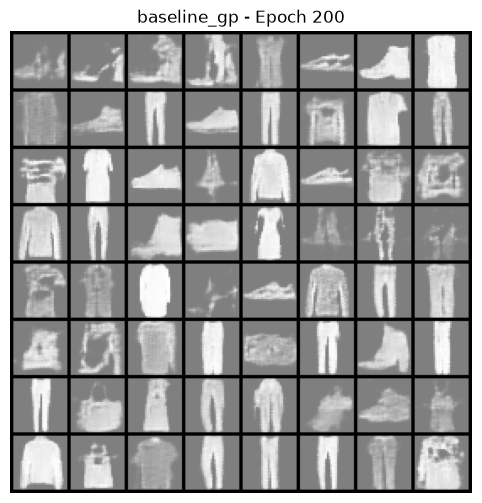

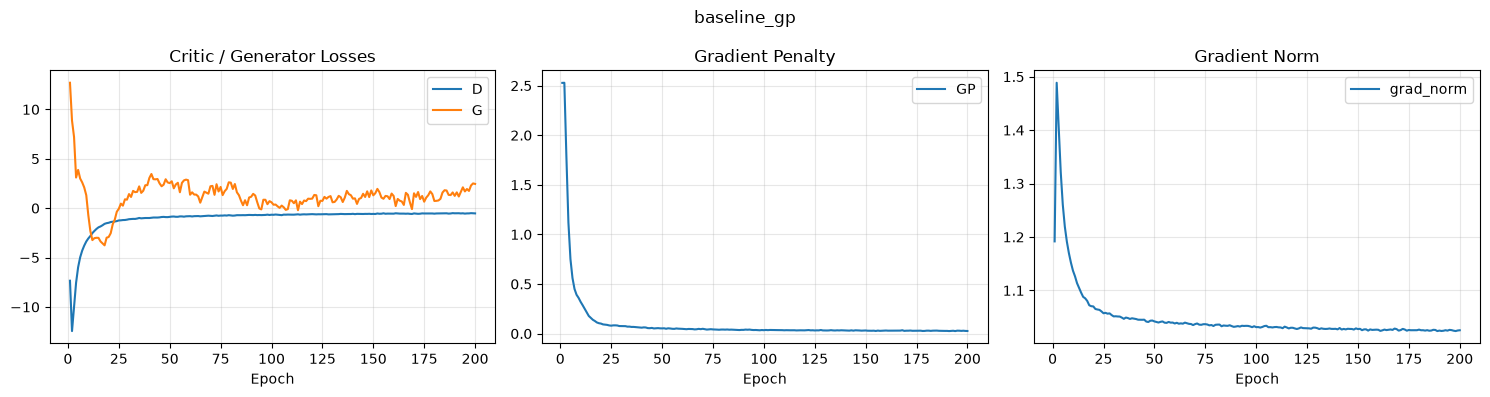

Completed experiment: baseline_gp

=============== lower_lr_gp ===============


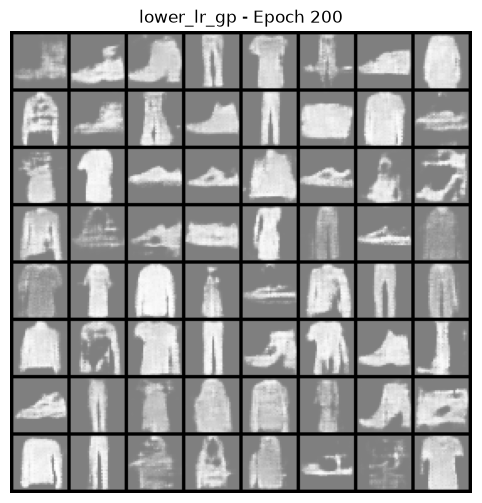

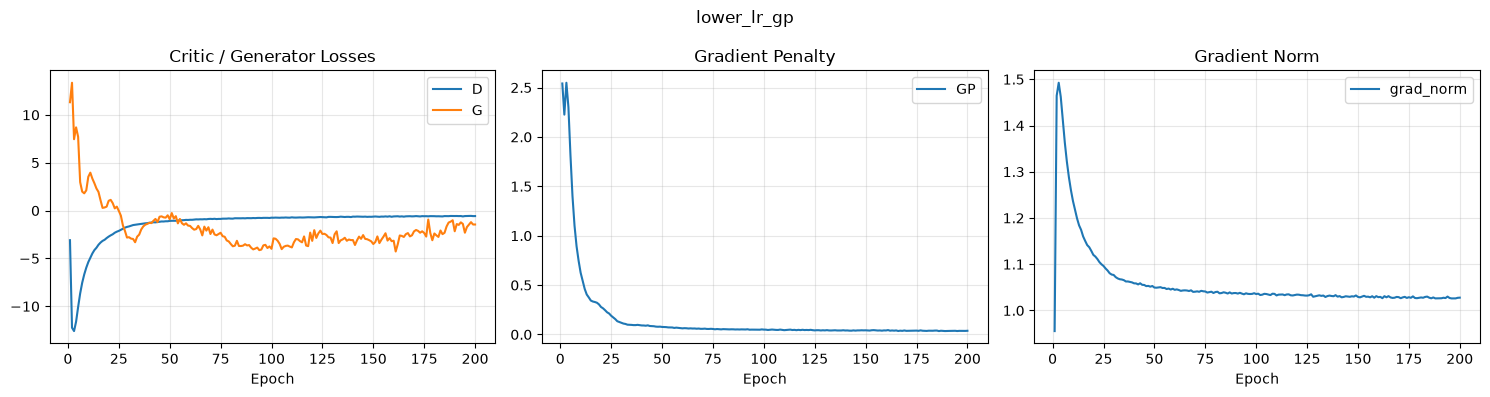

Completed experiment: lower_lr_gp

=============== larger_batch_gp ===============


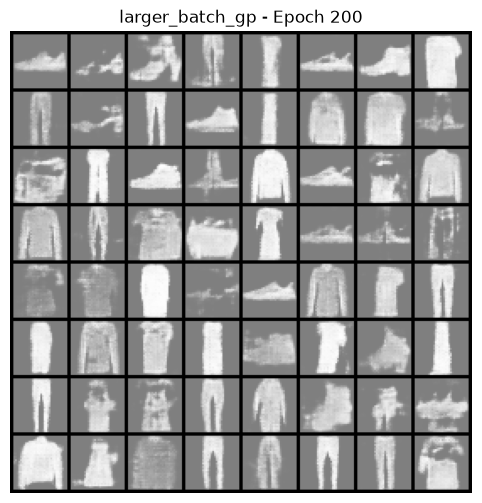

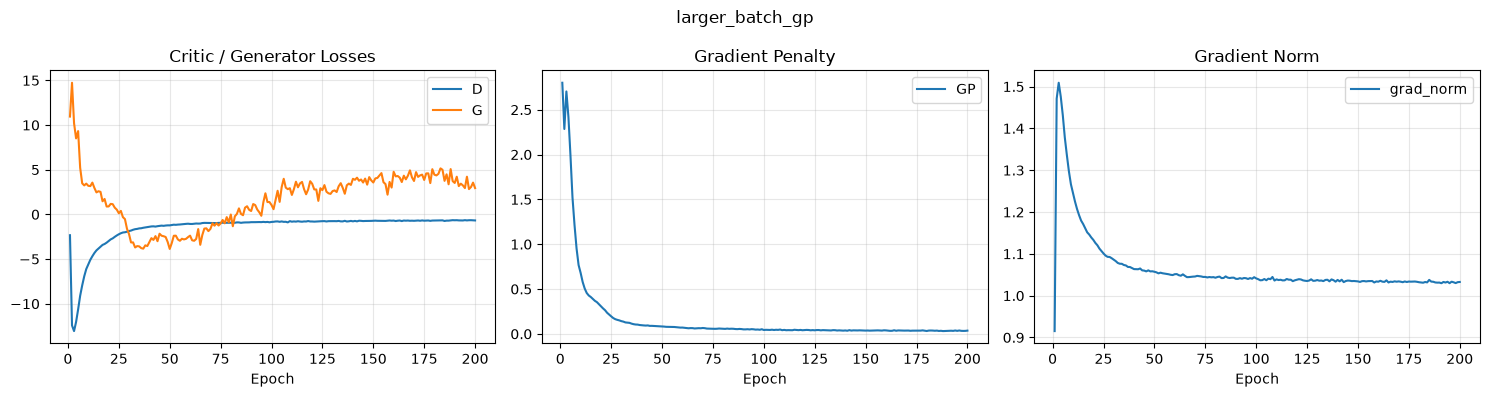

Completed experiment: larger_batch_gp

=============== fewer_critic_gp ===============


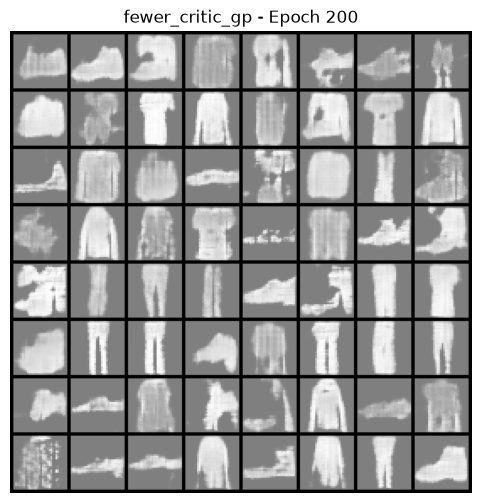

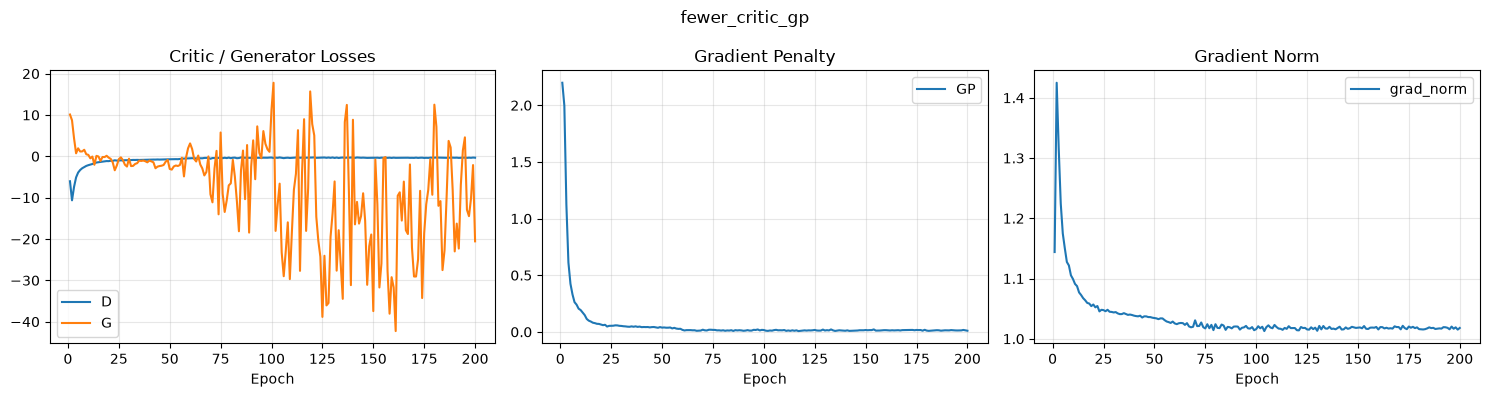

Completed experiment: fewer_critic_gp

=============== lower_penalty_gp ===============


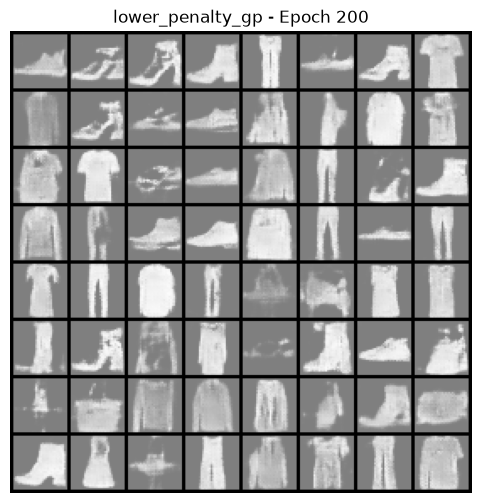

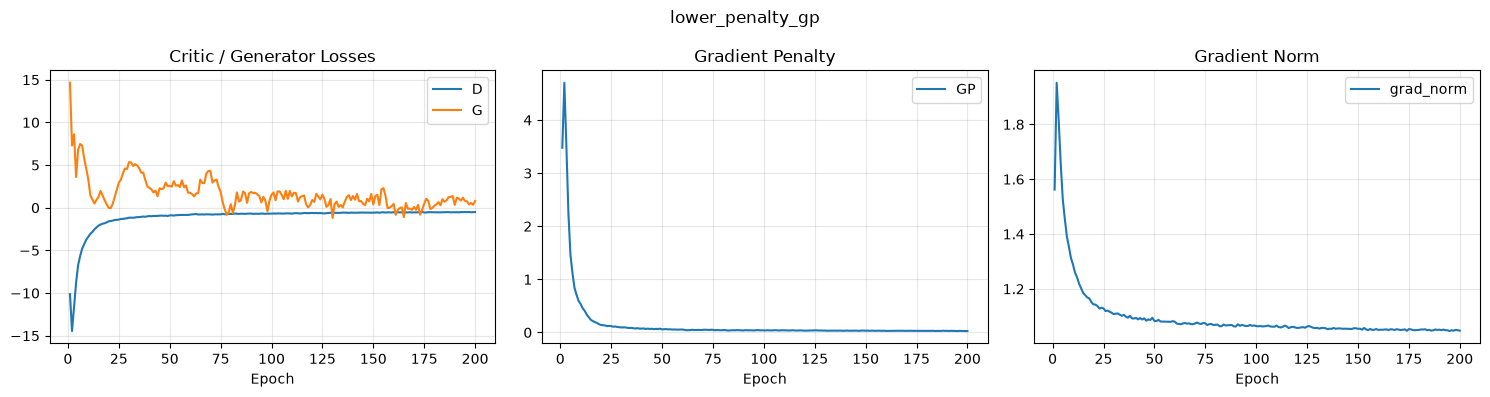

Completed experiment: lower_penalty_gp

=============== baseline_no_gp ===============


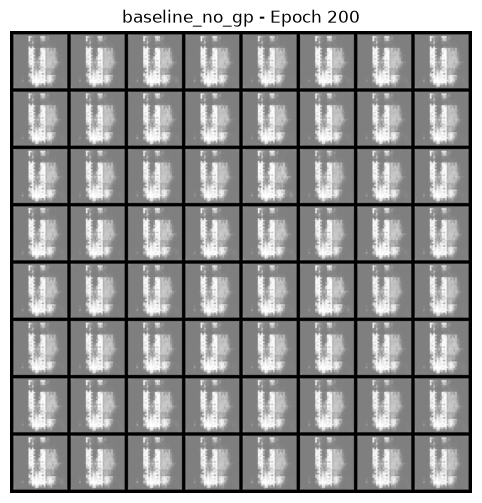

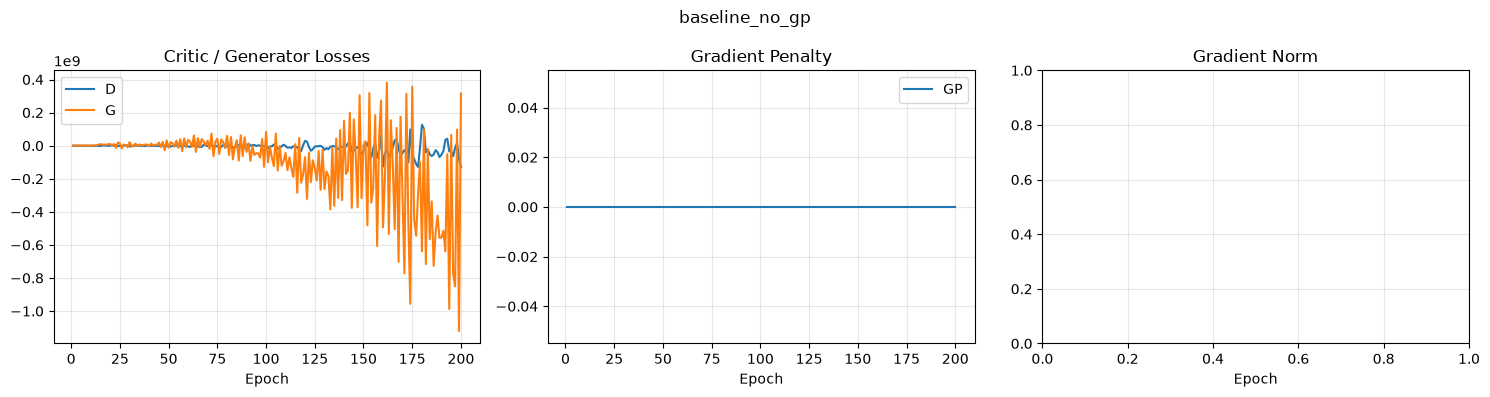

Completed experiment: baseline_no_gp

All experiments completed!
Saved results in: /workspace/wgan_gp_results


In [26]:

# === Run all experiments and save grids, curves, and metrics ===

import csv
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from torchvision.utils import save_image


# --------------------------------------------------
# 1. Plot epoch-level losses
# --------------------------------------------------

def draw_curves(history, save_path, title):

    epochs = [h["epoch"] for h in history]

    fig, axs = plt.subplots(1, 3, figsize=(15, 4))

    plots = [
        (["D", "G"], "Critic / Generator Losses"),
        (["GP"], "Gradient Penalty"),
        (["grad_norm"], "Gradient Norm")
    ]

    for ax, (keys, caption) in zip(axs, plots):

        for key in keys:
            values = [h[key] for h in history]

            if np.isfinite(values).any():
                ax.plot(epochs, values, label=key)

        ax.set_xlabel("Epoch")
        ax.set_title(caption)
        ax.grid(alpha=0.3)

        if ax.lines:
            ax.legend()

    fig.suptitle(title)
    fig.tight_layout()

    fig.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# --------------------------------------------------
# 2. Convert raw losses to epoch averages
# --------------------------------------------------

def epoch_average_losses(losses, batches_per_epoch, n_critic,
                         num_epochs):

    # The original Trainer updates D every batch and
    # G every n_critic batches.
    # Recover the actual generator-update counts.
    history = []
    global_step = 0
    generator_update_count = 0

    for epoch in range(1, num_epochs + 1):

        d_start = (epoch - 1) * batches_per_epoch
        d_end = min(epoch * batches_per_epoch, len(losses["D"]))

        # Number of G updates before and after this epoch
        g_start = d_start // n_critic
        g_end = d_end // n_critic

        row = {"epoch": epoch}

        for key in ["D", "GP", "grad_norm"]:
            values = losses[key][d_start:d_end]
            row[key] = (
                float(np.mean(values))
                if len(values) > 0
                else float("nan")
            )

        g_values = losses["G"][g_start:g_end]
        row["G"] = (
            float(np.mean(g_values))
            if len(g_values) > 0
            else float("nan")
        )

        history.append(row)

    return history


# --------------------------------------------------
# 3. Run all hyperparameter configurations
# --------------------------------------------------

all_histories = {}

for cfg in CONFIGS:

    print("\n" + "=" * 15, cfg["name"], "=" * 15)

    # Set random seed
    seed_everything(SEED)

    # Load MNIST using experiment batch size
    train_loader, _ = get_fashion_mnist_dataloaders(
        batch_size=cfg["batch_size"]
    )

    # Create experiment output folder
    run_dir = OUTPUT_ROOT / cfg["name"]
    run_dir.mkdir(parents=True, exist_ok=True)

    # Create fresh models for every experiment
    G = Generator(
        img_size=IMG_SIZE,
        latent_dim=LATENT_DIM,
        dim=DIM
    ).to(device)

    D = Discriminator(
        img_size=IMG_SIZE,
        dim=DIM
    ).to(device)

    # Create optimizers
    G_opt = torch.optim.Adam(
        G.parameters(),
        lr=cfg["lr"],
        betas=BETAS
    )

    D_opt = torch.optim.Adam(
        D.parameters(),
        lr=cfg["lr"],
        betas=BETAS
    )

    # Initialize original fixed Trainer
    trainer = Trainer(
        generator=G,
        discriminator=D,
        gen_optimizer=G_opt,
        dis_optimizer=D_opt,
        gp_weight=cfg["lambda_gp"],
        critic_iterations=cfg["n_critic"],
        print_every=PRINT_EVERY
    )

    # Fixed latent noise for consistent comparisons
    fixed_gen = torch.Generator().manual_seed(2026)

    fixed_z = torch.randn(
        (64, LATENT_DIM),
        generator=fixed_gen
    ).to(device)

    # ----------------------------------------------
    # Train
    # ----------------------------------------------

    losses = trainer.train(
        train_loader,
        epochs=EPOCHS,
        save_training_gif=False
    )

    # Convert training-step losses into epoch averages
    history = epoch_average_losses(
        losses,
        batches_per_epoch=len(train_loader),
        n_critic=cfg["n_critic"],
        num_epochs=EPOCHS
    )

    all_histories[cfg["name"]] = history

    # ----------------------------------------------
    # Save generated MNIST digit grid
    # ----------------------------------------------

    G.eval()

    with torch.no_grad():
        fake_images = G(fixed_z).detach().cpu()

    save_image(
        fake_images,
        run_dir / f"samples_epoch_{EPOCHS:03d}.png",
        nrow=8,
        padding=2,
        normalize=True,
        value_range=(-1, 1)
    )

    # Display generated digit samples
    fig, ax = plt.subplots(figsize=(6, 6))

    from torchvision.utils import make_grid

    grid = make_grid(
        fake_images,
        nrow=8,
        normalize=True,
        value_range=(-1, 1)
    )

    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.axis("off")
    ax.set_title(f"{cfg['name']} - Epoch {EPOCHS}")

    plt.show()
    plt.close(fig)

    # ----------------------------------------------
    # Save loss curves
    # ----------------------------------------------

    draw_curves(
        history,
        run_dir / "loss_curves.png",
        cfg["name"]
    )

    # ----------------------------------------------
    # Save epoch metrics
    # ----------------------------------------------

    with open(run_dir / "metrics.csv", "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=["epoch", "D", "G", "GP", "grad_norm"]
        )

        writer.writeheader()
        writer.writerows(history)

    # ----------------------------------------------
    # Save experiment configuration
    # ----------------------------------------------

    with open(run_dir / "config.json", "w") as f:
        json.dump(
            {
                **cfg,
                "epochs": EPOCHS,
                "seed": SEED,
                "betas": BETAS
            },
            f,
            indent=2
        )

    # ----------------------------------------------
    # Save trained models
    # ----------------------------------------------

    torch.save(
        {
            "generator": G.state_dict(),
            "critic": D.state_dict(),
            "config": cfg,
            "epochs": EPOCHS
        },
        run_dir / "checkpoint.pt"
    )

    print(f"Completed experiment: {cfg['name']}")


print("\nAll experiments completed!")
print("Saved results in:", OUTPUT_ROOT.resolve())




### Best WGAN-GP Run on Fashion-MNIST

After comparing the generated Fashion-MNIST samples and training curves from the 200-epoch experiments, I selected `baseline_gp` as the best configuration.

**Selected Hyperparameters:**
- Learning rate: 0.0001
- Batch size: 128
- Critic iterations (`n_critic`): 5
- Gradient penalty coefficient (`lambda_GP`): 10
- Adam betas: (0.9, 0.99)
- Training epochs: 200

Both `baseline_gp` and `larger_batch_gp` generated recognizable clothing items. However, the baseline produced slightly more consistent images and exhibited relatively stable generator and critic loss curves during later training.

Both configurations showed decreasing gradient penalties and gradient norms approaching 1, indicating that gradient regularization was working as intended.

### Best Fashion-MNIST Run: Samples and Training Curves

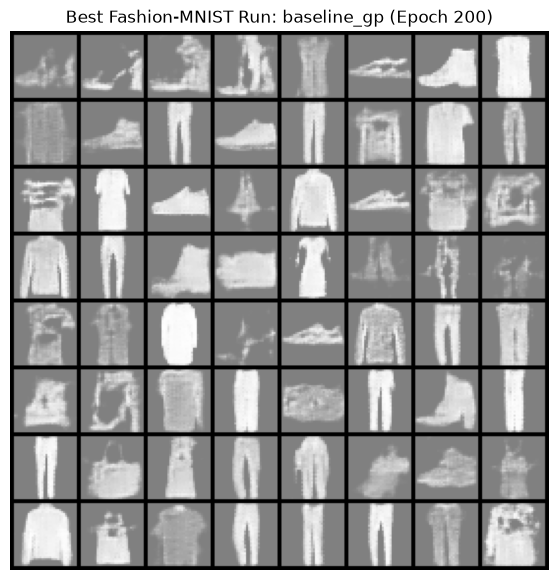

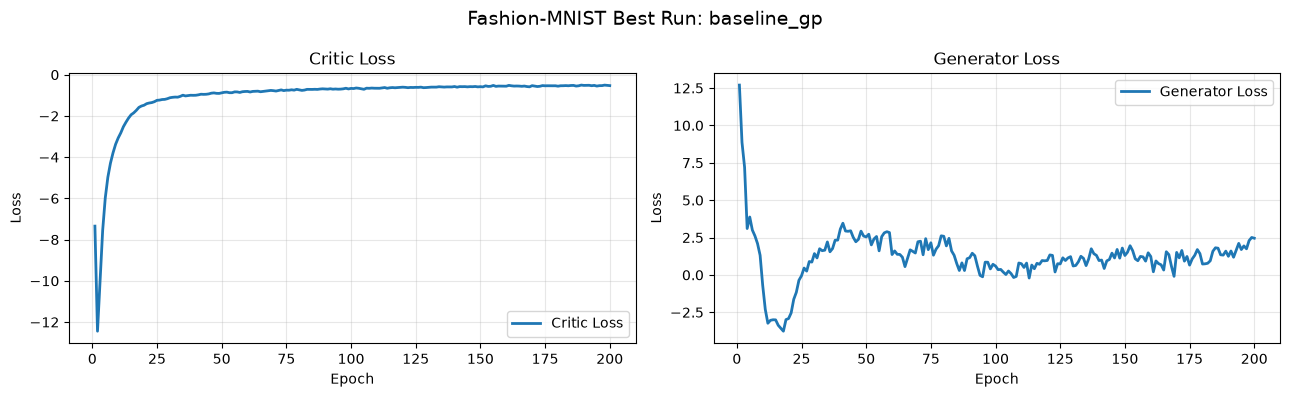

Best Fashion-MNIST Run: baseline_gp
Final Critic Loss: -0.5288
Final Generator Loss: 2.4562
Saved loss curves to: /workspace/wgan_gp_results/baseline_gp/best_fashion_loss_curves.png


In [30]:

# === Best Fashion-MNIST Run: Samples and Training Curves ===

from pathlib import Path
from PIL import Image
import csv
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Select best Fashion-MNIST experiment
# --------------------------------------------------

BEST_FASHION_RUN = "baseline_gp"

# Use the folder where Fashion-MNIST results were saved
FASHION_ROOT = Path("/workspace/wgan_gp_results")

run_dir = FASHION_ROOT / BEST_FASHION_RUN

# --------------------------------------------------
# 2. Display generated clothing samples
# --------------------------------------------------

sample_path = run_dir / "samples_epoch_200.png"

if sample_path.exists():
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(Image.open(sample_path))
    ax.axis("off")
    ax.set_title(
        f"Best Fashion-MNIST Run: {BEST_FASHION_RUN} (Epoch 200)"
    )
    plt.show()
else:
    print("Image not found:", sample_path)

# --------------------------------------------------
# 3. Load training metrics
# --------------------------------------------------

metrics_path = run_dir / "metrics.csv"

with open(metrics_path, "r") as f:
    history = list(csv.DictReader(f))

epochs = [int(row["epoch"]) for row in history]
critic_losses = [float(row["D"]) for row in history]
generator_losses = [float(row["G"]) for row in history]

# --------------------------------------------------
# 4. Plot critic and generator losses
# --------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Critic loss
axs[0].plot(
    epochs,
    critic_losses,
    label="Critic Loss",
    linewidth=2
)
axs[0].set_title("Critic Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(alpha=0.3)

# Generator loss
axs[1].plot(
    epochs,
    generator_losses,
    label="Generator Loss",
    linewidth=2
)
axs[1].set_title("Generator Loss")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Loss")
axs[1].legend()
axs[1].grid(alpha=0.3)

plt.suptitle(
    f"Fashion-MNIST Best Run: {BEST_FASHION_RUN}",
    fontsize=14
)

plt.tight_layout()

# --------------------------------------------------
# 5. Save loss curves
# --------------------------------------------------

save_path = run_dir / "best_fashion_loss_curves.png"

plt.savefig(
    save_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 6. Print final training metrics
# --------------------------------------------------

print("Best Fashion-MNIST Run:", BEST_FASHION_RUN)
print("Final Critic Loss:", round(critic_losses[-1], 4))
print("Final Generator Loss:", round(generator_losses[-1], 4))
print("Saved loss curves to:", save_path)



### Comparison: WGAN-GP on MNIST vs. Fashion-MNIST

**Generated Samples**

I trained WGAN-GP on MNIST and Fashion-MNIST for 200 epochs and compared their generated samples.

On MNIST, the generator produced recognizable handwritten digits with relatively clear shapes and good diversity. Some samples were distorted, but most resembled actual digits.

On Fashion-MNIST, the generator produced recognizable clothing items, including shoes, shirts, trousers, and sweaters. However, some samples were blurrier and contained less clearly defined details compared with MNIST.

**Training Curves**

The critic and generator loss curves were used to examine training behavior across both datasets.

On MNIST, gradient penalty helped maintain controlled critic gradients, with final gradient norms close to 1. The Fashion-MNIST experiments also completed training with gradient penalty enabled, although the generated images showed some remaining distortions.

The loss values were not used as direct measures of image quality because critic and generator losses can differ between datasets and independently trained models.

**Hyperparameter and Architecture Changes**

No changes to the generator or critic architecture were required when switching from MNIST to Fashion-MNIST.

Both datasets were resized to 32×32 grayscale images, allowing the same WGAN-GP architecture and training procedure to be reused.

The baseline configuration was:

- Learning rate: 0.0001
- Batch size: 128
- Critic iterations (`n_critic`): 5
- Gradient penalty (`lambda_GP`): 10
- Adam betas: (0.9, 0.99)
- Training epochs: 200

I also evaluated different learning rates, batch sizes, critic iterations, and gradient penalty coefficients.

**Conclusion**

WGAN-GP generated recognizable samples on both datasets without requiring architecture changes. However, Fashion-MNIST samples showed more visual distortions and less clearly defined details than MNIST digits.

This suggests that Fashion-MNIST was more challenging for the generator because clothing images contain more varied shapes and textures.
